Accuracy: 0.98


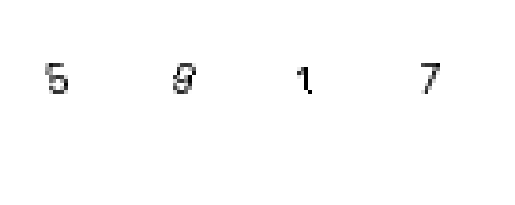

Actual CAPTCHA: 5917
Predicted CAPTCHA: 5917


In [2]:
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from skimage.feature import hog

random.seed(42)
np.random.seed(42)

chars = "0123456789"
W, H = 32, 48

def create_image(char):
    img = Image.new("L", (W, H), 255)
    draw = ImageDraw.Draw(img)
    font = ImageFont.load_default()
    draw.text((10, 12), char, fill=0, font=font)
    return img.rotate(random.randint(-10, 10), fillcolor=255)

def extract(img):
    return hog(np.array(img.resize((W, H))),
               orientations=9,
               pixels_per_cell=(8, 8),
               cells_per_block=(2, 2))

# Generate training dataset
X, y = [], []
for c in chars:
    for _ in range(200):
        X.append(extract(create_image(c)))
        y.append(c)

X, y = np.array(X), np.array(y)

# Train model
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = SVC(kernel="linear")
model.fit(X_train, y_train)

print("Accuracy:", accuracy_score(y_test, model.predict(X_test)))

# Generate sample CAPTCHA
actual = "".join(random.choices(chars, k=4))
captcha = Image.new("L", (W * 4, H), 255)

for i, c in enumerate(actual):
    captcha.paste(create_image(c), (i * W, 0))

# Predict CAPTCHA
result = ""
for i in range(4):
    crop = captcha.crop((i * W, 0, (i + 1) * W, H))
    result += model.predict([extract(crop)])[0]

plt.imshow(captcha, cmap="gray")
plt.axis("off")
plt.show()

print("Actual CAPTCHA:", actual)
print("Predicted CAPTCHA:", result)